# Pregunta 2: Snap roll de un quadcópter para evitar obtáculos

| Kamt, L., Reyes, K.

Se desea trasladar un quadcopter desde una posición inicial hasta una posición final, **evitando dos obstáculos esféricos**, respetando limites de actuación e inclinacion y terminando en reposo con una orientación prescrita. 

In [2]:
# Librerias para la optimizacion, el calculo numerico, las figuras y la animacion
import casadi as ca
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, Image, display
import io

plt.rcParams.update({"figure.dpi": 115, "axes.grid": True, "grid.alpha": 0.25})

# Mostrar una figura como PNG incrustado en el notebook, independientemente
# del backend de Matplotlib; asi los graficos quedan guardados en el archivo
def mostrar_figura(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=115, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))


## 1. Inicialización

Se utiliza el sistema inercial con $z$ positivo hacia arriba, la gravedad en $-z$, y ángulos de Euler **roll-pitch-yaw** $(\phi,\theta,\psi)$ (convencion $ZYX$). El estado, de dimension 12, es

$$
\boldsymbol{x}=\begin{bmatrix}\boldsymbol{p}^T&\boldsymbol{\eta}^T&\boldsymbol{v}^T&\boldsymbol{\omega}^T\end{bmatrix}^T,
\quad
\boldsymbol{p}=\begin{bmatrix}x&y&z\end{bmatrix}^T,\quad
\boldsymbol{\eta}=\begin{bmatrix}\phi&\theta&\psi\end{bmatrix}^T.
$$

Aquí $\boldsymbol{v}=\dot{\boldsymbol{p}}$ se expresa en el sistema inercial, mientras que $\boldsymbol{\omega}=[p_b,q_b,r_b]^T$ se expresa en el sistema del cuerpo. **No** debe confundirse $\boldsymbol{\omega}$ con $\dot{\boldsymbol{\eta}}$.

Las cuatro entradas son el **empuje total** $F$ (dirigido a lo largo del eje $z$ del cuerpo) y los tres momentos de control:

$$\boldsymbol{u}=\begin{bmatrix}F&\tau_x&\tau_y&\tau_z\end{bmatrix}^T.$$

Este modelo utiliza las entradas equivalentes de un quadcopter; no se modela individualmente la velocidad de sus cuatro motores.

In [3]:
# Parametros fisicos de un quadcopter pequeno
m = 1.0                          # Masa total [kg]
g = 9.81                         # Aceleracion gravitacional [m/s^2]
I = np.array([0.02, 0.02, 0.04])  # Momentos de inercia principales [kg m^2]

# Duracion y discretizacion: 70 intervalos de shooting, sin comparacion con Euler
T = 8.0                          # Horizonte temporal [s]
N = 70                           # Numero de intervalos de shooting
h = T/N                         # Duracion de un intervalo [s]
t = np.linspace(0, T, N+1)       # Instantes nodales, incluyendo t=0 y t=T

# Condicion inicial: posicion, angulos de Euler, velocidad lineal y angular
p_ini = np.array([0.0, 0.0, 1.0])
p_fin = np.array([4.0, 2.0, 1.3])
x_ini = np.r_[p_ini, np.zeros(9)]

# El objetivo prescribe una guiñada final de 90 grados, pero sin roll ni pitch
# Tambien exige que las velocidades lineal y angular finales sean nulas
x_fin = np.r_[p_fin, [0.0, 0.0, np.pi/2], np.zeros(6)]

# Obstaculos: centro (x,y,z) y radio fisico [m]
centros = np.array([[1.60, 0.80, 1.15],
                    [2.90, 1.45, 1.25]])
radios = np.array([0.63, 0.58])

# Para la planificacion, el quadcopter se aproxima mediante una esfera
# El radio de seguridad incluye su tamano (0.18 m) y un margen (0.02 m)
radio_robot = 0.18
margen = 0.02
radios_seg = radios + radio_robot + margen

# Limites de los actuadores y de la inclinacion (roll y pitch)
F_max = 2*m*g                  # Empuje total permitido, desde 0 hasta 2 m g
tau_max = 0.40                 # Magnitud maxima de cada momento [N m]
angulo_max = 0.55              # Aproximadamente 31.5 grados, en radianes
z_min, z_max = 0.30, 2.80     # Limites de altura [m]

print(f"Estado: 12 componentes; control: 4 componentes; {N} intervalos")
print(f"Inicio: {p_ini}; objetivo: {p_fin}; yaw final: {np.degrees(x_fin[5]):.0f} grados")
print(f"Radios efectivos de los obstaculos: {radios_seg} m")


Estado: 12 componentes; control: 4 componentes; 70 intervalos
Inicio: [0. 0. 1.]; objetivo: [4.  2.  1.3]; yaw final: 90 grados
Radios efectivos de los obstaculos: [0.83 0.78] m


La dinámica de traslacion y rotación de un cuerpo rígido es

$$
\dot{\boldsymbol p}=\boldsymbol v,\qquad
m\dot{\boldsymbol v}=F R(\boldsymbol\eta)\boldsymbol e_3-mg\boldsymbol e_3,
$$
$$
\dot{\boldsymbol\eta}=E(\phi,\theta)\boldsymbol\omega,\qquad
I\dot{\boldsymbol\omega}=\boldsymbol\tau-\boldsymbol\omega\times(I\boldsymbol\omega).
$$

Se utiliza $R=R_z(\psi)R_y(\theta)R_x(\phi)$, que transforma vectores del cuerpo al sistema inercial, y $\boldsymbol e_3=[0,0,1]^T$. La matriz que relaciona las velocidades angulares del cuerpo con las derivadas de Euler es

$$
E(\phi,\theta)=\begin{bmatrix}
1&\sin\phi\tan\theta&\cos\phi\tan\theta\\
0&\cos\phi&-\sin\phi\\
0&\frac{\sin\phi}{\cos\theta}&\frac{\cos\phi}{\cos\theta}
\end{bmatrix}.
$$

La representación Euler presenta singularidad para $\cos\theta=0$; en este ejemplo se evita al imponer un limite estricto sobre pitch. El modelo completo queda expresado como $\dot{\boldsymbol x}=\boldsymbol f(\boldsymbol x,\boldsymbol u)$.

In [4]:
# Variables simbolicas. CasADi construye expresiones diferenciables para IPOPT
xs = ca.SX.sym("x", 12)  # [x,y,z, roll,pitch,yaw, vx,vy,vz, wx,wy,wz]
us = ca.SX.sym("u", 4)   # [F, tau_x, tau_y, tau_z]

phi, theta, psi = xs[3], xs[4], xs[5]
wx, wy, wz = xs[9], xs[10], xs[11]

# Tercera columna de R = Rz(psi) Ry(theta) Rx(phi)
# Solo esta columna es necesaria para convertir el empuje al sistema inercial
e3_rotado = ca.vertcat(
    ca.cos(psi)*ca.sin(theta)*ca.cos(phi) + ca.sin(psi)*ca.sin(phi),
    ca.sin(psi)*ca.sin(theta)*ca.cos(phi) - ca.cos(psi)*ca.sin(phi),
    ca.cos(theta)*ca.cos(phi)
)

# Relacion exacta entre omega del cuerpo y velocidad de angulos de Euler
eta_dot = ca.vertcat(
    wx + ca.sin(phi)*ca.tan(theta)*wy + ca.cos(phi)*ca.tan(theta)*wz,
    ca.cos(phi)*wy - ca.sin(phi)*wz,
    (ca.sin(phi)*wy + ca.cos(phi)*wz)/ca.cos(theta)
)

# Aceleracion del centro de masa en coordenadas inerciales
v_dot = us[0]/m * e3_rotado - ca.vertcat(0, 0, g)

# Ecuacion de Euler del cuerpo rigido, con matriz de inercia diagonal
I_mat = ca.diag(ca.DM(I))
omega = xs[9:12]
omega_dot = ca.solve(I_mat, us[1:4] - ca.cross(omega, I_mat @ omega))

# Vector de derivadas en el MISMO orden que el estado
xdot = ca.vertcat(xs[6:9], eta_dot, v_dot, omega_dot)
f = ca.Function("f", [xs, us], [xdot])

# Comprobacion inicial: empuje mg y velocidades nulas producen hover
u_hover = np.array([m*g, 0.0, 0.0, 0.0])
print("Derivada en hover:", np.round(np.array(f(x_ini, u_hover)).ravel(), 10))


Derivada en hover: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 2. Multiple shooting con RK4

Se divide $[0,T]$ en $N$ intervalos. Las variables de optimización son los **estados nodales** $\boldsymbol x_1,\ldots,\boldsymbol x_N$ y los controles constantes en cada intervalo $\boldsymbol u_0,\ldots,\boldsymbol u_{N-1}$. La condición inicial $\boldsymbol x_0$ es conocida y, por tanto, no se optimiza.

En cada intervalo, la dinámica se integra con RK4 para obtener el propagador $\Phi_h$; en este caso se emplean **dos subpasos RK4** por intervalo. El NLP impone

$$\boxed{\boldsymbol x_{k+1}-\Phi_h(\boldsymbol x_k,\boldsymbol u_k)=\boldsymbol 0},\qquad k=0,\ldots,N-1.$$

Estas igualdades son las **restricciones de continuidad** del *multiple shooting*. Las variables $\boldsymbol x_{k+1}$ y el estado integrado desde $\boldsymbol x_k$ se calculan independientemente antes de imponer su igualdad.

Se utiliza un costo cuadratico discreto que penaliza la desviacion respecto de una referencia nominal suave, la velocidad, la inclinacion, la velocidad angular, el esfuerzo respecto de hover y cambios abruptos del control:

$$
\begin{aligned}
J={}&\sum_{k=0}^{N-1}h\Big[
2\|\boldsymbol p_k-\boldsymbol p_{\mathrm{ref},k}\|^2
+0.09\|\boldsymbol v_k\|^2+0.5(\phi_k^2+\theta_k^2)\\
&\qquad+0.12(\psi_k-\psi_{\mathrm{ref},k})^2
+0.035\|\boldsymbol\omega_k\|^2+0.025(F_k-mg)^2
+0.25\|\boldsymbol\tau_k\|^2\Big]\\
&+0.02\sum_{k=1}^{N-1}\|\boldsymbol u_k-\boldsymbol u_{k-1}\|^2.
\end{aligned}
$$

La referencia nominal interpola entre ambos extremos mediante $\sigma(s)=10s^3-15s^4+6s^5$, con $s=t/T$. **La referencia pasa cerca o a través de los obstáculos**, de modo que el optimizador debe modificar la trayectoria para cumplir las restricciones.

También se impone la condición terminal **completa** $\boldsymbol x_N=\boldsymbol x_f$, cotas de altura y ángulos, cotas de actuación y, para cada obstaculo $j$,

$$\boxed{\|\boldsymbol p-\boldsymbol c_j\|^2\geq (r_j+r_{\mathrm{robot}}+m_{\mathrm{seg}})^2}.$$

Para detectar mejor posibles acercamientos entre nodos, se evalúan los obstáculos y las cotas de estado tanto en los **nodos** como en el **punto medio integrado** de cada intervalo. Aun así, son restricciones muestreadas, no una garantia matemática para todo instante continuo.

In [5]:
# PASO A: definir el integrador RK4 para medio intervalo de shooting
# Como el control es constante en el intervalo, se utiliza el mismo uk dos veces
# El punto medio resultante tambien servira para evaluar las desigualdades
zz = ca.SX.sym("z", 12)
vv = ca.SX.sym("v", 4)
dt = h/2                           # Paso interno: mitad del intervalo nodal

k1 = f(zz, vv)
k2 = f(zz + dt/2*k1, vv)
k3 = f(zz + dt/2*k2, vv)
k4 = f(zz + dt*k3, vv)

# Un subpaso RK4; devuelve el estado al final de h/2
RK4_medio = ca.Function("RK4_medio", [zz, vv],
                        [zz + (dt/6)*(k1 + 2*k2 + 2*k3 + k4)])

# El intervalo completo de shooting se integra aplicando dos subpasos
Phi_RK4 = ca.Function("Phi_RK4", [zz, vv],
                       [RK4_medio(RK4_medio(zz, vv), vv)])

print(f"Un intervalo de {h:.4f} s usa dos subpasos RK4 de {dt:.4f} s")


Un intervalo de 0.1143 s usa dos subpasos RK4 de 0.0571 s


**Construcción del NLP:** cada columna de `X` representa un estado nodal; sus ultimas $N$ columnas son variables de decision. Para cada intervalo se calcula el punto medio integrado, se imponen las igualdades de continuidad y se agregan las restricciones fisicas. Las desigualdades de distancia a obstáculos hacen que el NLP sea no convexo.

In [6]:
# PASO B: crear las variables de optimizacion con CasADi Opti
opti = ca.Opti()
X_libre = opti.variable(12, N)    # Estados x_1,...,x_N: 12*N variables
U = opti.variable(4, N)           # Entradas u_0,...,u_(N-1): 4*N variables

# El estado inicial no es variable: primera columna constante seguida de las libres
X = ca.horzcat(ca.DM(x_ini), X_libre)

# Funcional de costo que se construira acumulando los costos de cada intervalo
J = 0

for k in range(N):
    xk = X[:, k]                   # Estado en el inicio del intervalo k
    uk = U[:, k]                   # Entrada mantenida constante durante el intervalo

    # Integrar la dinamica en la mitad y luego hasta el final del intervalo
    x_medio = RK4_medio(xk, uk)
    x_integrado = RK4_medio(x_medio, uk)

    # Restriccion de multiple shooting: enlazar el estado integrado con x_(k+1)
    opti.subject_to(X[:, k+1] == x_integrado)

    # Referencia nominal: quintica, con derivadas primera y segunda nulas
    # en los extremos. No constituye necesariamente una trayectoria factible
    s = k/N
    sigma = 10*s**3 - 15*s**4 + 6*s**5
    p_ref = p_ini + (p_fin - p_ini)*sigma
    yaw_ref = (np.pi/2)*sigma

    # Costo de seguimiento de posicion y guiñada
    error_p = xk[0:3] - ca.DM(p_ref)
    error_yaw = xk[5] - yaw_ref

    # Penalizar las velocidades, la inclinacion, los momentos y el empuje
    # desviado del hover F=mg (asi se evita penalizar el empuje imprescindible)
    J += h*(
        2*ca.dot(error_p, error_p)
        + 0.09*ca.dot(xk[6:9], xk[6:9])
        + 0.5*ca.dot(xk[3:5], xk[3:5])
        + 0.12*error_yaw**2
        + 0.035*ca.dot(xk[9:12], xk[9:12])
        + 0.025*(uk[0] - m*g)**2
        + 0.25*ca.dot(uk[1:4], uk[1:4])
    )

    # Penalizacion de variaciones del control entre intervalos consecutivos
    # Se omite para k=0 porque no hay control anterior dentro del horizonte
    if k > 0:
        J += 0.02*ca.sumsqr(uk - U[:, k-1])

    # Restricciones de altura, roll, pitch y obstaculos
    # Para k=0, xk es conocido: basta imponer las desigualdades en x_medio
    # Para k>=1, los nodos son variables y tambien se restringen
    puntos_a_restringir = [x_medio] if k == 0 else [xk, x_medio]
    for estado in puntos_a_restringir:
        opti.subject_to(opti.bounded(z_min, estado[2], z_max))
        opti.subject_to(opti.bounded(-angulo_max, estado[3], angulo_max))
        opti.subject_to(opti.bounded(-angulo_max, estado[4], angulo_max))

        # Distancia al cuadrado >= radio de exclusion al cuadrado
        # No hay raiz cuadrada: expresion suave para la diferenciacion automatica
        for centro, radio_seg in zip(centros, radios_seg):
            opti.subject_to(ca.sumsqr(estado[0:3] - ca.DM(centro)) >= radio_seg**2)

# Condicion terminal completa: posicion, orientacion y velocidades especificadas
opti.subject_to(X[:, -1] == ca.DM(x_fin))

# Limites de empuje y de los momentos (todas las columnas de U)
opti.subject_to(opti.bounded(0, U[0, :], F_max))
opti.subject_to(opti.bounded(-tau_max, U[1:4, :], tau_max))

# Objetivo y solucionador
opti.minimize(J)
opti.solver("ipopt", {"expand": False, "print_time": False},
            {"print_level": 0, "max_iter": 1500, "tol": 1e-7,
             "acceptable_tol": 1e-6, "mu_strategy": "adaptive"})

print(f"Variables de decision: {12*N} estados + {4*N} controles = {16*N}")
print(f"Igualdades dinamicas: {12*N}; igualdades terminales: 12")


Variables de decision: 840 estados + 280 controles = 1120
Igualdades dinamicas: 840; igualdades terminales: 12


**Inicialización y solucion:** se utiliza como estimacion inicial una trayectoria suave que se aparta lateralmente y en altura de la línea recta. Esta propuesta se usa **solo para inicializar IPOPT**: el resultado final lo determinan la dinámica, las restricciones y el costo. Las velocidades se estiman derivando numéricamente la posición propuesta y los pequenos ángulos iniciales se aproximan a partir de la aceleracion deseada.

In [7]:
# Tiempo normalizado s y polinomio quintico sigma(s)
s = t/T
sigma = 10*s**3 - 15*s**4 + 6*s**5

# Posicion inicialmente propuesta: avance suave mas un desvio temporal
# El desvio lateral y la elevacion desaparecen al inicio y al final
p_propuesta = p_ini[:, None] + (p_fin - p_ini)[:, None]*sigma[None, :]
p_propuesta[1, :] += 1.30*np.sin(np.pi*s)**2  # Desvio lateral [m]
p_propuesta[2, :] += 0.65*np.sin(np.pi*s)**2  # Elevacion adicional [m]

# Derivar la posicion respecto del tiempo para inicializar velocidad y aceleracion
v_propuesta = np.gradient(p_propuesta, h, axis=1, edge_order=2)
a_propuesta = np.gradient(v_propuesta, h, axis=1, edge_order=2)

# Referencia inicial de yaw: rotacion gradual de 0 a 90 grados
yaw_propuesto = (np.pi/2)*sigma

# Aproximacion para roll y pitch a partir de la aceleracion horizontal
# Para angulos pequenos y yaw arbitrario:
# theta ~= (cos(yaw)*ax + sin(yaw)*ay)/g
# phi   ~= (sin(yaw)*ax - cos(yaw)*ay)/g
phi_propuesto = (np.sin(yaw_propuesto)*a_propuesta[0] -
                 np.cos(yaw_propuesto)*a_propuesta[1])/g
theta_propuesto = (np.cos(yaw_propuesto)*a_propuesta[0] +
                   np.sin(yaw_propuesto)*a_propuesta[1])/g
eta_propuesta = np.vstack((phi_propuesto, theta_propuesto, yaw_propuesto))

# Aproximacion inicial de velocidades angulares con derivadas de Euler
# El optimizador corregira la diferencia respecto de las velocidades del cuerpo
omega_propuesta = np.gradient(eta_propuesta, h, axis=1, edge_order=2)

# Ensamblar el vector completo, manteniendo el orden del modelo de 12 estados
x_propuesta = np.vstack((p_propuesta, eta_propuesta, v_propuesta, omega_propuesta))

# Entradas iniciales: empuje cercano a mg + m*az, y momentos inicialmente nulos
u_propuesta = np.vstack((m*(g + a_propuesta[2, :-1]), np.zeros((3, N))))

opti.set_initial(X_libre, x_propuesta[:, 1:])
opti.set_initial(U, u_propuesta)

# Resolver el NLP no convexo. Esta trayectoria inicial ayuda a elegir
# una familia de trayectorias que pase alrededor de los obstaculos
sol = opti.solve()
x_opt = np.asarray(sol.value(X))   # Estados nodales optimos: matriz 12 x (N+1)
u_opt = np.asarray(sol.value(U))   # Entradas optimas: matriz 4 x N

print("Estado del solver:", opti.stats()["return_status"])
print("Iteraciones IPOPT:", opti.stats()["iter_count"])
print(f"Costo final: {sol.value(J):.6f}")
print("Error terminal (norma):", np.linalg.norm(x_opt[:, -1] - x_fin))



******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

Estado del solver: Solve_Succeeded
Iteraciones IPOPT: 21
Costo final: 3.409907
Error terminal (norma): 3.3525718942750964e-31


## 3. Resultados y verificación

La solucion del NLP satisface las igualdades de RK4 y las restricciones impuestas en los puntos muestreados. Para evaluar su fidelidad respecto del modelo continuo, **se integra nuevamente desde el estado inicial**, manteniendo cada entrada $\boldsymbol u_k$ constante durante su intervalo, pero utilizando ahora el integrador adaptativo `solve_ivp` (DOP853), con tolerancias estrictas. Esta verificación es independiente del esquema RK4 utilizado por el NLP.

Se comprueban tres aspectos diferentes: continuidad en los nodos, error entre nodos optimizados y simulados, y distancia de la simulación respecto de los obstáculos. Las distancias se comparan tanto con el radio físico ampliado por el radio del robot como con el margen adicional especificado para la optimización.

In [8]:
# Integracion independiente, desde el estado inicial y con el control optimizado
# En cada intervalo se evalua la solucion en 21 instantes (20 divisiones)
t_sim = [0.0]
trayectoria = [x_ini.copy()]
x_actual = x_ini.copy()

for k in range(N):
    uk = u_opt[:, k]                      # Control constante del intervalo k
    instantes_locales = np.linspace(0, h, 21)

    # DOP853 es diferente de RK4 fijo: sirve como verificacion numerica
    resultado = solve_ivp(
        lambda tiempo, estado: np.asarray(f(estado, uk)).ravel(),
        (0, h), x_actual, method="DOP853", t_eval=instantes_locales,
        rtol=1e-10, atol=1e-11
    )

    # No duplicar el inicio del intervalo: ya es el ultimo punto del previo
    t_sim.extend(k*h + resultado.t[1:])
    trayectoria.extend(resultado.y[:, 1:].T)

    # El intervalo siguiente comienza donde termina la integracion continua
    x_actual = resultado.y[:, -1].copy()

t_sim = np.asarray(t_sim)
x_sim = np.asarray(trayectoria).T           # Matriz 12 x (20*N+1)
x_sim_nodos = x_sim[:, ::20]              # Submuestrear en los instantes nodales

# Defectos de continuidad, evaluados a posteriori sobre los nodos del NLP
defectos = np.column_stack([
    x_opt[:, k+1] - np.asarray(Phi_RK4(x_opt[:, k], u_opt[:, k])).ravel()
    for k in range(N)
])

# Distancia al obstaculo menos el radio geometrico del obstaculo y del robot
# Positivo = no hay colision geometrica bajo esta aproximacion esferica
holguras_fisicas = np.vstack([
    np.linalg.norm(x_sim[0:3, :]-centro[:, None], axis=0) - (radio+radio_robot)
    for centro, radio in zip(centros, radios)
])

# Margen adicional previsto por el optimizador, medido en la simulacion fina
holguras_seguridad = np.vstack([
    np.linalg.norm(x_sim[0:3, :]-centro[:, None], axis=0) - radio_seg
    for centro, radio_seg in zip(centros, radios_seg)
])

print(f"Maximo defecto dinamico RK4: {np.max(np.abs(defectos)):.2e}")
print(f"Maxima diferencia estado NLP / integracion independiente: "
      f"{np.max(np.abs(x_opt-x_sim_nodos)):.2e}")
print(f"Error terminal en integracion independiente: "
      f"{np.linalg.norm(x_sim[:, -1]-x_fin):.2e}")
for j in range(len(radios)):
    print(f"Obstaculo {j+1}: holgura geometrica minima = "
          f"{holguras_fisicas[j].min():+.4f} m; "
          f"holgura respecto del margen adicional = "
          f"{holguras_seguridad[j].min():+.4f} m")

# Una holgura marginalmente negativa contra el radio de SEGURIDAD es posible
# entre nodos: los obstaculos se impusieron solo en nodos y puntos medios
# La validacion fina comprueba si el modelo fisico realmente evita la colision


Maximo defecto dinamico RK4: 1.02e-10
Maxima diferencia estado NLP / integracion independiente: 1.40e-04
Error terminal en integracion independiente: 1.70e-04
Obstaculo 1: holgura geometrica minima = +0.0200 m; holgura respecto del margen adicional = -0.0000 m
Obstaculo 2: holgura geometrica minima = +0.0199 m; holgura respecto del margen adicional = -0.0001 m


Las figuras siguientes permiten identificar como se desvian las trayectorias para evitar los obstáculos y como evolucionan el estado y los controles. Las esferas translúcidas representan el **radio físico** de los obstáculos; el NLP utiliza radios de exclusion mayores para considerar el tamano del robot y el margen adicional.

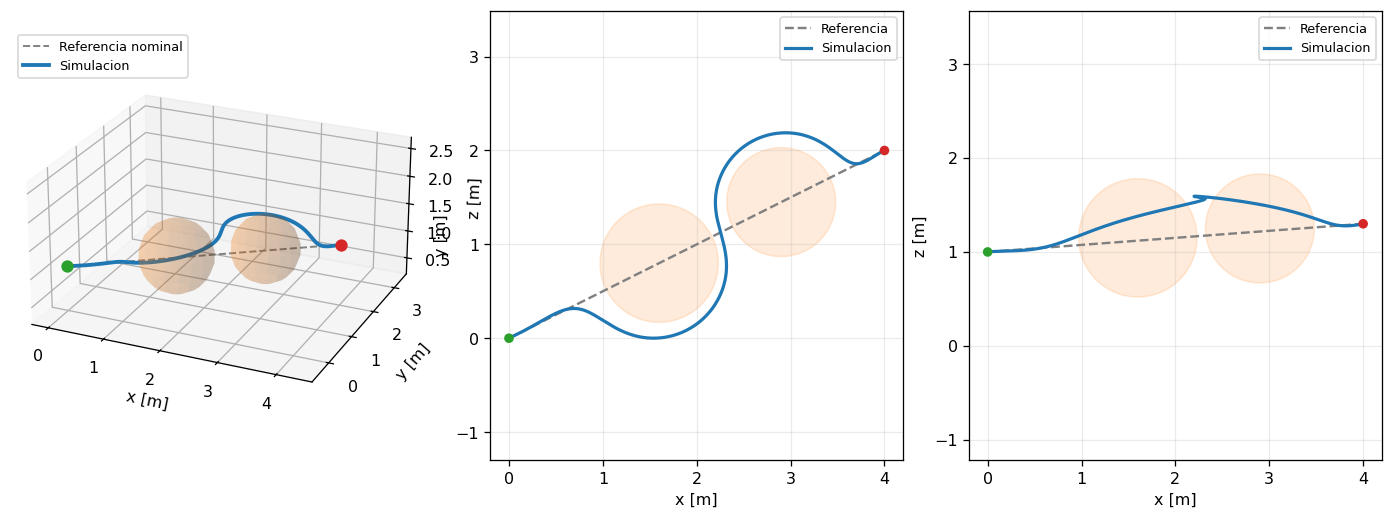

In [9]:
# Funcion geometrica que reutilizaremos en la figura y en la animacion
def dibujar_esfera(ax, centro, radio, color="tab:orange", transparencia=0.17):
    # Parametrizacion esferica de una superficie 3D
    azimut = np.linspace(0, 2*np.pi, 18)
    polar = np.linspace(0, np.pi, 10)
    xx = centro[0] + radio*np.outer(np.cos(azimut), np.sin(polar))
    yy = centro[1] + radio*np.outer(np.sin(azimut), np.sin(polar))
    zz = centro[2] + radio*np.outer(np.ones_like(azimut), np.cos(polar))
    ax.plot_surface(xx, yy, zz, color=color, alpha=transparencia,
                    linewidth=0, shade=True)

# Dibujar posicion 3D y proyecciones. Usamos la MISMA trayectoria simulada
fig = plt.figure(figsize=(12, 4.4), constrained_layout=True)
ax3d = fig.add_subplot(131, projection="3d")
axxy = fig.add_subplot(132)
axz = fig.add_subplot(133)

# Posicion nominal (quintica): no contempla las restricciones de obstaculos
p_nominal = p_ini[:, None] + (p_fin-p_ini)[:, None]*sigma[None, :]

for centro, radio in zip(centros, radios):
    dibujar_esfera(ax3d, centro, radio)
    # Cortes esquematicos circulares de cada obstaculo: no son proyecciones
    # exactas de toda la esfera, pero muestran su extension lateral/vertical
    ang = np.linspace(0, 2*np.pi, 120)
    axxy.fill(centro[0] + radio*np.cos(ang),
              centro[1] + radio*np.sin(ang), color="tab:orange", alpha=0.15)
    axz.fill(centro[0] + radio*np.cos(ang),
             centro[2] + radio*np.sin(ang), color="tab:orange", alpha=0.15)

ax3d.plot(*p_nominal, "--", color="0.5", lw=1.2, label="Referencia nominal")
ax3d.plot(*x_sim[0:3], color="tab:blue", lw=2.4, label="Simulacion")
ax3d.scatter(*p_ini, color="tab:green", s=45)
ax3d.scatter(*p_fin, color="tab:red", s=45)
ax3d.set(xlabel="x [m]", ylabel="y [m]", zlabel="z [m]",
         xlim=(-0.3, 4.6), ylim=(-0.7, 3.6), zlim=(0.2, 2.7))
ax3d.set_box_aspect((4.9, 4.3, 2.5))
ax3d.view_init(elev=24, azim=-66)
ax3d.legend(fontsize=8, loc="upper left")

for ax, iz, zlab in [(axxy, 1, "y [m]"), (axz, 2, "z [m]")]:
    ax.plot(p_nominal[0], p_nominal[iz], "--", color="0.5", label="Referencia")
    ax.plot(x_sim[0], x_sim[iz], color="tab:blue", lw=2, label="Simulacion")
    ax.scatter([p_ini[0], p_fin[0]], [p_ini[iz], p_fin[iz]],
               c=["tab:green", "tab:red"], s=25, zorder=4)
    ax.set(xlabel="x [m]", ylabel=zlab)
    ax.axis("equal")
    ax.legend(fontsize=8)
mostrar_figura(fig)


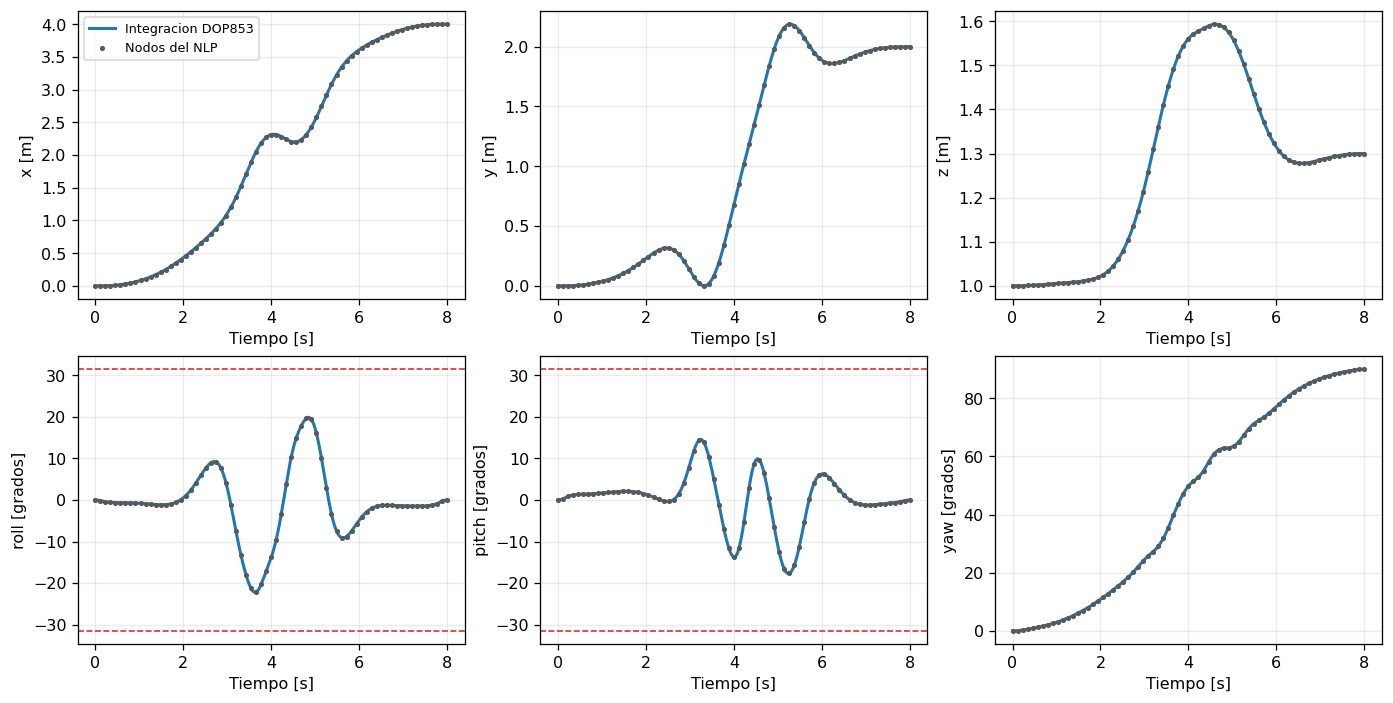

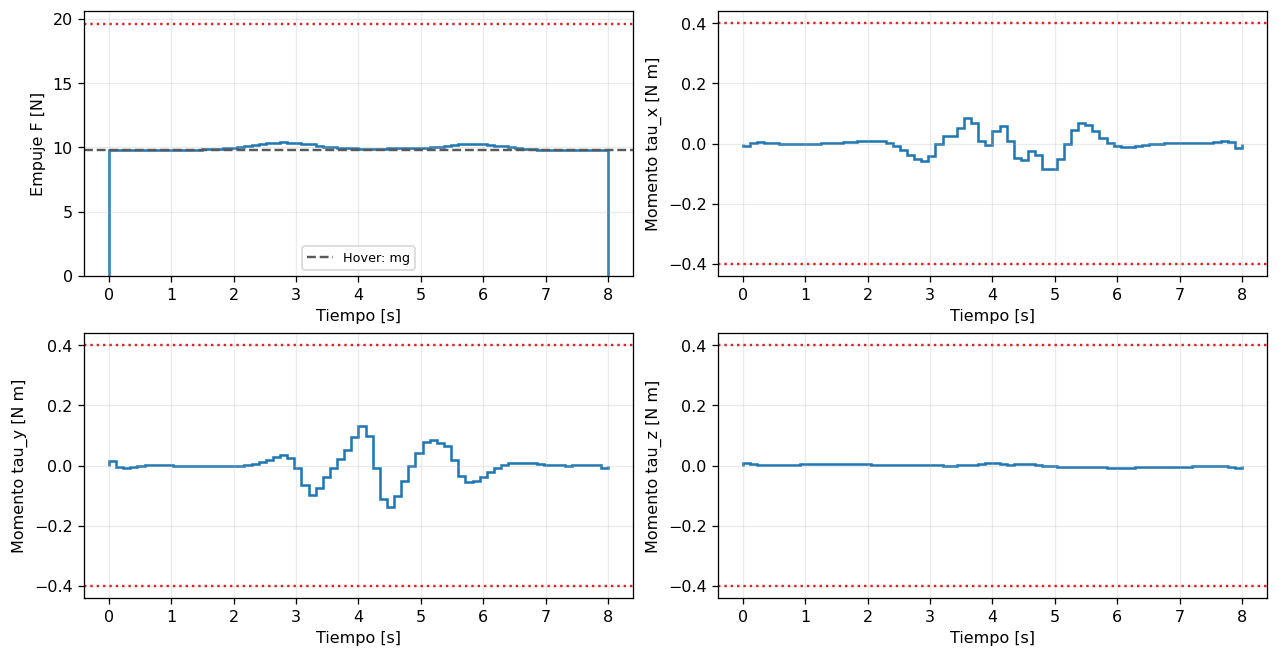

In [10]:
# Comparacion de posicion y angulos entre nodos del NLP e integracion fina
fig, axs = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
nom_estado = ["x [m]", "y [m]", "z [m]", "roll [grados]", "pitch [grados]", "yaw [grados]"]

for j, ax in enumerate(axs.flat):
    factor = 1.0 if j < 3 else 180/np.pi  # Angulos en grados solo al graficar
    ax.plot(t_sim, x_sim[j]*factor, color="tab:blue", lw=1.9,
            label="Integracion DOP853")
    ax.plot(t, x_opt[j]*factor, "o", color="0.35", markersize=2.2,
            label="Nodos del NLP")
    ax.set(xlabel="Tiempo [s]", ylabel=nom_estado[j])
    if j in (3, 4):
        ax.axhline(np.degrees(angulo_max), color="tab:red", ls="--", lw=1)
        ax.axhline(-np.degrees(angulo_max), color="tab:red", ls="--", lw=1)
axs[0, 0].legend(fontsize=8)
mostrar_figura(fig)

# Control optimo: constante a trozos en los N intervalos
fig, axs = plt.subplots(2, 2, figsize=(11, 5.6), constrained_layout=True)
nombres_u = ["Empuje F [N]", "Momento tau_x [N m]", "Momento tau_y [N m]", "Momento tau_z [N m]"]
for j, ax in enumerate(axs.flat):
    ax.stairs(u_opt[j], t, color="tab:blue", linewidth=1.6)
    ax.set(xlabel="Tiempo [s]", ylabel=nombres_u[j])
    if j == 0:
        ax.axhline(m*g, ls="--", color="0.35", label="Hover: mg")
        ax.axhline(F_max, ls=":", color="tab:red")
        ax.legend(fontsize=8)
    else:
        ax.axhline(tau_max, ls=":", color="tab:red")
        ax.axhline(-tau_max, ls=":", color="tab:red")
mostrar_figura(fig)


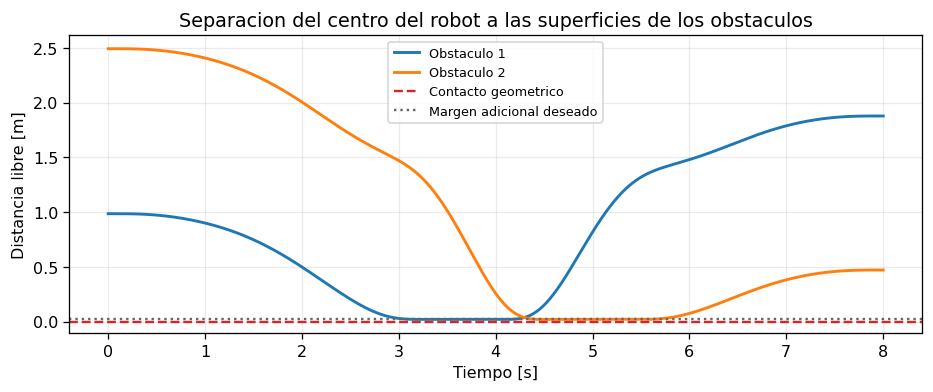

In [11]:
# Verificar tambien las distancias geometricas de la simulacion completa
fig, ax = plt.subplots(figsize=(8, 3.3), constrained_layout=True)
for j in range(len(radios)):
    ax.plot(t_sim, holguras_fisicas[j], lw=1.8, label=f"Obstaculo {j+1}")
ax.axhline(0, ls="--", color="tab:red", label="Contacto geometrico")
ax.axhline(margen, ls=":", color="0.4", label="Margen adicional deseado")
ax.set(xlabel="Tiempo [s]", ylabel="Distancia libre [m]",
       title="Separacion del centro del robot a las superficies de los obstaculos")
ax.legend(fontsize=8)
mostrar_figura(fig)


## 4. Visualización del movimiento

Para representar el quadcopter, se toman sus dos brazos como segmentos del sistema del cuerpo y se calculan sus posiciones en el espacio mediante la rotación $R(\phi,\theta,\psi)$. Asi pueden observarse tanto el **movimiento tridimensional** como los cambios de roll, pitch y yaw. El trazo azul muestra la trayectoria seguida; las esferas naranjas son los obstáculos.

La animación utiliza los estados obtenidos en la **simulación independiente**, no una interpolación artificial entre los estados de optimización. El cuerpo del quadcopter se dibuja a escala ilustrativa; los obstáculos del NLP ya consideran una envolvente esférica conservadora.

In [12]:
# Rotacion del marco del cuerpo hacia el marco inercial, segun ZYX
# Esta funcion se usa para las dos direcciones de los brazos en CADA frame
def rotacion_cuerpo(phi, theta, psi):
    cf, sf = np.cos(phi), np.sin(phi)
    ct, st = np.cos(theta), np.sin(theta)
    cp, sp = np.cos(psi), np.sin(psi)
    return np.array([
        [cp*ct, cp*st*sf-sp*cf, cp*st*cf+sp*sf],
        [sp*ct, sp*st*sf+cp*cf, sp*st*cf-cp*sf],
        [-st,   ct*sf,           ct*cf]
    ])

# Elegir aproximadamente 65 frames para que la animacion sea ligera
indices = np.linspace(0, len(t_sim)-1, 65, dtype=int)
brazo = 0.17                      # Longitud del centro a cada rotor [m]

# Preparar la escena fija: trayectoria de referencia, obstaculos y ejes
fig = plt.figure(figsize=(8, 5.5), dpi=80)
ax = fig.add_subplot(111, projection="3d")
for centro, radio in zip(centros, radios):
    dibujar_esfera(ax, centro, radio, transparencia=0.24)
ax.plot(*x_sim[0:3], color="0.72", ls="--", lw=1, alpha=0.8)
ax.scatter(*p_ini, color="tab:green", s=48, label="Inicio")
ax.scatter(*p_fin, color="tab:red", s=48, label="Objetivo")

# Los cuatro rotores se colocan en extremos de dos brazos perpendiculares
linea_trayectoria, = ax.plot([], [], [], color="tab:blue", lw=2.2)
brazo_x, = ax.plot([], [], [], color="tab:blue", lw=3, marker="o", markersize=5)
brazo_y, = ax.plot([], [], [], color="tab:purple", lw=3, marker="o", markersize=5)
centro_robot, = ax.plot([], [], [], "ko", markersize=5)

ax.set(xlabel="x [m]", ylabel="y [m]", zlabel="z [m]",
       xlim=(-0.4, 4.6), ylim=(-0.8, 3.6), zlim=(0.2, 2.8))
ax.set_box_aspect((5.0, 4.4, 2.6))
ax.view_init(elev=27, azim=-67)
ax.legend(loc="upper left", fontsize=9)

# Cada frame actualiza SOLO los artistas asociados al vehiculo y su estela
def actualizar(frame):
    j = indices[frame]            # Indice de la simulacion continua
    pos = x_sim[0:3, j]           # Posicion del centro del quadcopter
    phi, theta, psi = x_sim[3:6, j]
    R = rotacion_cuerpo(phi, theta, psi)

    # Direcciones de los dos brazos del quadcopter, rotadas al mundo
    dx = R @ np.array([brazo, 0, 0])
    dy = R @ np.array([0, brazo, 0])
    px = np.column_stack((pos-dx, pos+dx))
    py = np.column_stack((pos-dy, pos+dy))

    brazo_x.set_data_3d(px[0], px[1], px[2])
    brazo_y.set_data_3d(py[0], py[1], py[2])
    centro_robot.set_data_3d([pos[0]], [pos[1]], [pos[2]])
    linea_trayectoria.set_data_3d(x_sim[0, :j+1], x_sim[1, :j+1], x_sim[2, :j+1])
    ax.set_title(f"Quadcopter 3D | t = {t_sim[j]:.2f} s | yaw = {np.degrees(psi):.1f} grados")
    return linea_trayectoria, brazo_x, brazo_y, centro_robot

animacion = FuncAnimation(fig, actualizar, frames=len(indices), interval=65,
                         blit=False, repeat=True)
plt.close(fig)  # No mostrar un fotograma estatico duplicado

# El HTML incluye sus fotogramas, con botones de reproduccion y pausa
display(HTML(animacion.to_jshtml(fps=17, default_mode="loop")))


Referencias: [CasADi](https://web.casadi.org/docs/), [IPOPT](https://coin-or.github.io/Ipopt/), [SciPy `solve_ivp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html).